# Cleaning one histology section

`cleanslide` removes mounting artifacts from a histology section and returns a
tissue mask, a registration-ready grayscale image, and the colour section with
its background removed.

This demo runs the whole pipeline on a single section and shows what each stage
contributes. It needs the optional plotting extra:

```bash
pip install 'cleanslide[qc]'
```

Every size parameter is a physical quantity in micrometres, converted to pixels
from the section's own pixel size.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cleanslide import CleanParams, clean_section, um_to_px

## The section

Point `CLEANSLIDE_DEMO_SECTION` at a brightfield histology section — this demo
was run on a NextBrain LFB section at 4.0 um/px. Without one, a synthetic
section is generated so the notebook still runs end to end.

The pixel size matters more than anything else here: every filter is sized in
micrometres and converted through it, so a wrong value does not raise an error,
it silently rescales the whole pipeline.

sub-NBP5816_sample-A2109_stain-LFB_BF.tif
14492 x 11480 px at 4.0 um/px


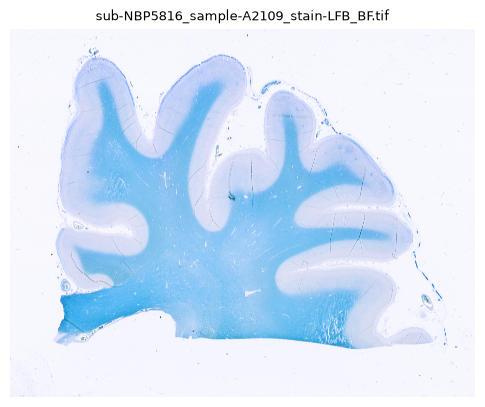

In [2]:
def load_section():
    """Return (image, pixel_size_um, label) from the environment or synthesise one."""
    path = os.environ.get("CLEANSLIDE_DEMO_SECTION", "")
    if path and Path(path).exists():
        import cv2
        cv2.setUseOptimized(True)
        bgr = cv2.imread(path, cv2.IMREAD_COLOR)
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        return rgb, float(os.environ.get("CLEANSLIDE_DEMO_PIXEL_SIZE_UM", 4.0)), Path(path).name

    import cv2
    rng = np.random.default_rng(0)
    rgb = np.full((900, 700, 3), 248, np.uint8)
    cv2.ellipse(rgb, (350, 450), (250, 380), 0, 0, 360, (150, 130, 180), -1)
    cv2.ellipse(rgb, (350, 450), (140, 240), 0, 0, 360, (95, 75, 130), -1)
    rgb = np.clip(rgb + rng.normal(0, 6, rgb.shape), 0, 255).astype(np.uint8)
    cv2.circle(rgb, (300, 330), 47, (248, 248, 248), -1)      # a mounting bubble
    return rgb, 31.75, "synthetic section (no demo image found)"


rgb, pixel_size_um, label = load_section()
print(f"{label}\n{rgb.shape[1]} x {rgb.shape[0]} px at {pixel_size_um} um/px")

plt.figure(figsize=(6, 7))
plt.imshow(rgb)
plt.title(label, fontsize=9)
plt.axis("off")
plt.show()

## Running the pipeline

One call. Nothing else is configured: the background level, the dust threshold
and the contrast endpoints are all estimated from this section, because they
depend on the scan rather than on the tissue.

`keep_stages=True` retains the intermediate images so we can look at them; a
batch run leaves it off and keeps only the outputs.

In [3]:
result = clean_section(rgb, pixel_size_um, keep_stages=True)

print("estimated from the image:")
for key in ("background_threshold", "dust_threshold",
            "normalise_low", "normalise_high"):
    if key in result.info:
        print(f"  {key:24} {result.info[key]}")

estimated from the image:
  background_threshold     245
  dust_threshold           69.48
  normalise_low            9.0
  normalise_high           112.0


## The three outputs

- **grayscale** — inverted so tissue is bright on a black background, then
  stretched to the full range. This is what a registration step consumes.
- **tissue mask** — binary mask. 
- **colour** — the section with the background removed.
  Keeps the stain visible, which the inverted grayscale no longer does.

### Why the grayscale is inverted

Not cosmetic. These sections are registered to a **T1 MRI**, so the cleaned
image is made to resemble a T1 as closely as possible.

| | white matter | grey matter | background |
|---|---|---|---|
| T1 MRI | bright | darker | dark |
| stained histology | **dark** (myelin takes the stain) | lighter | **near-white** (glass) |
| after inversion | bright | darker | dark (set to 0) |

Inverting restores the T1 ordering, and the background is set to 0 rather than
inverted to white, which matches a skull-stripped T1. The registration's
similarity measure then compares like with like instead of having to bridge an
inverted contrast.

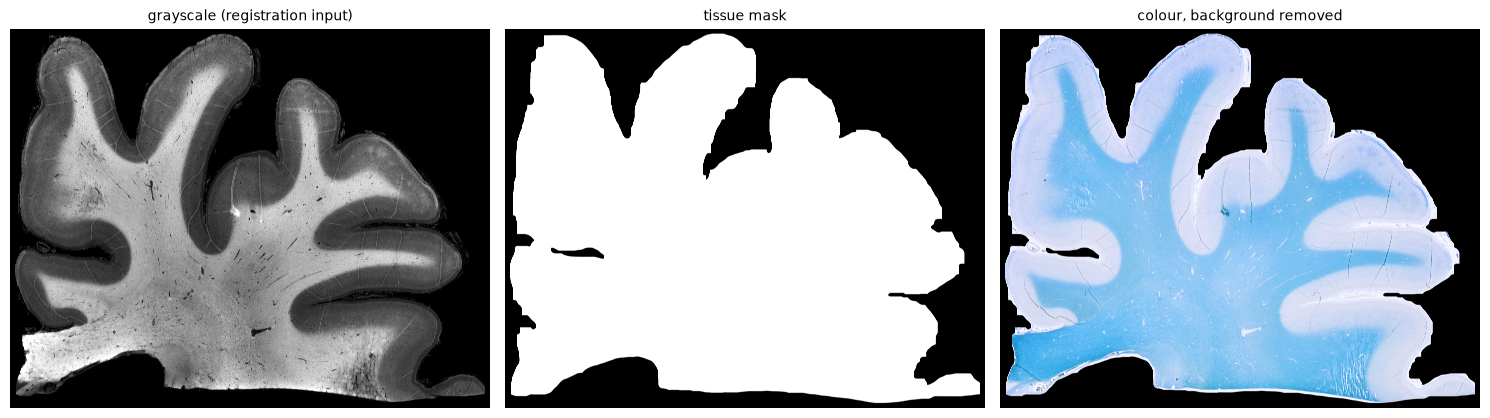

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for axis, (image, title) in zip(axes, [
        (result.clean, "grayscale (registration input)"),
        (result.mask, "tissue mask"),
        (result.rgb, "colour, background removed")]):
    axis.imshow(image, cmap=None if image.ndim == 3 else "gray",
                vmin=None if image.ndim == 3 else 0,
                vmax=None if image.ndim == 3 else 255)
    axis.set_title(title, fontsize=10)
    axis.axis("off")
plt.tight_layout()
plt.show()

## What each stage did

Reading left to right:
- the mask isolates tissue from glass
- round bubbles are inpainted out of the colour image
- inversion makes tissue bright
- the stretch opens up the compressed range a pale stain inverts into
- dust specks are removed before the final contrast enhancement

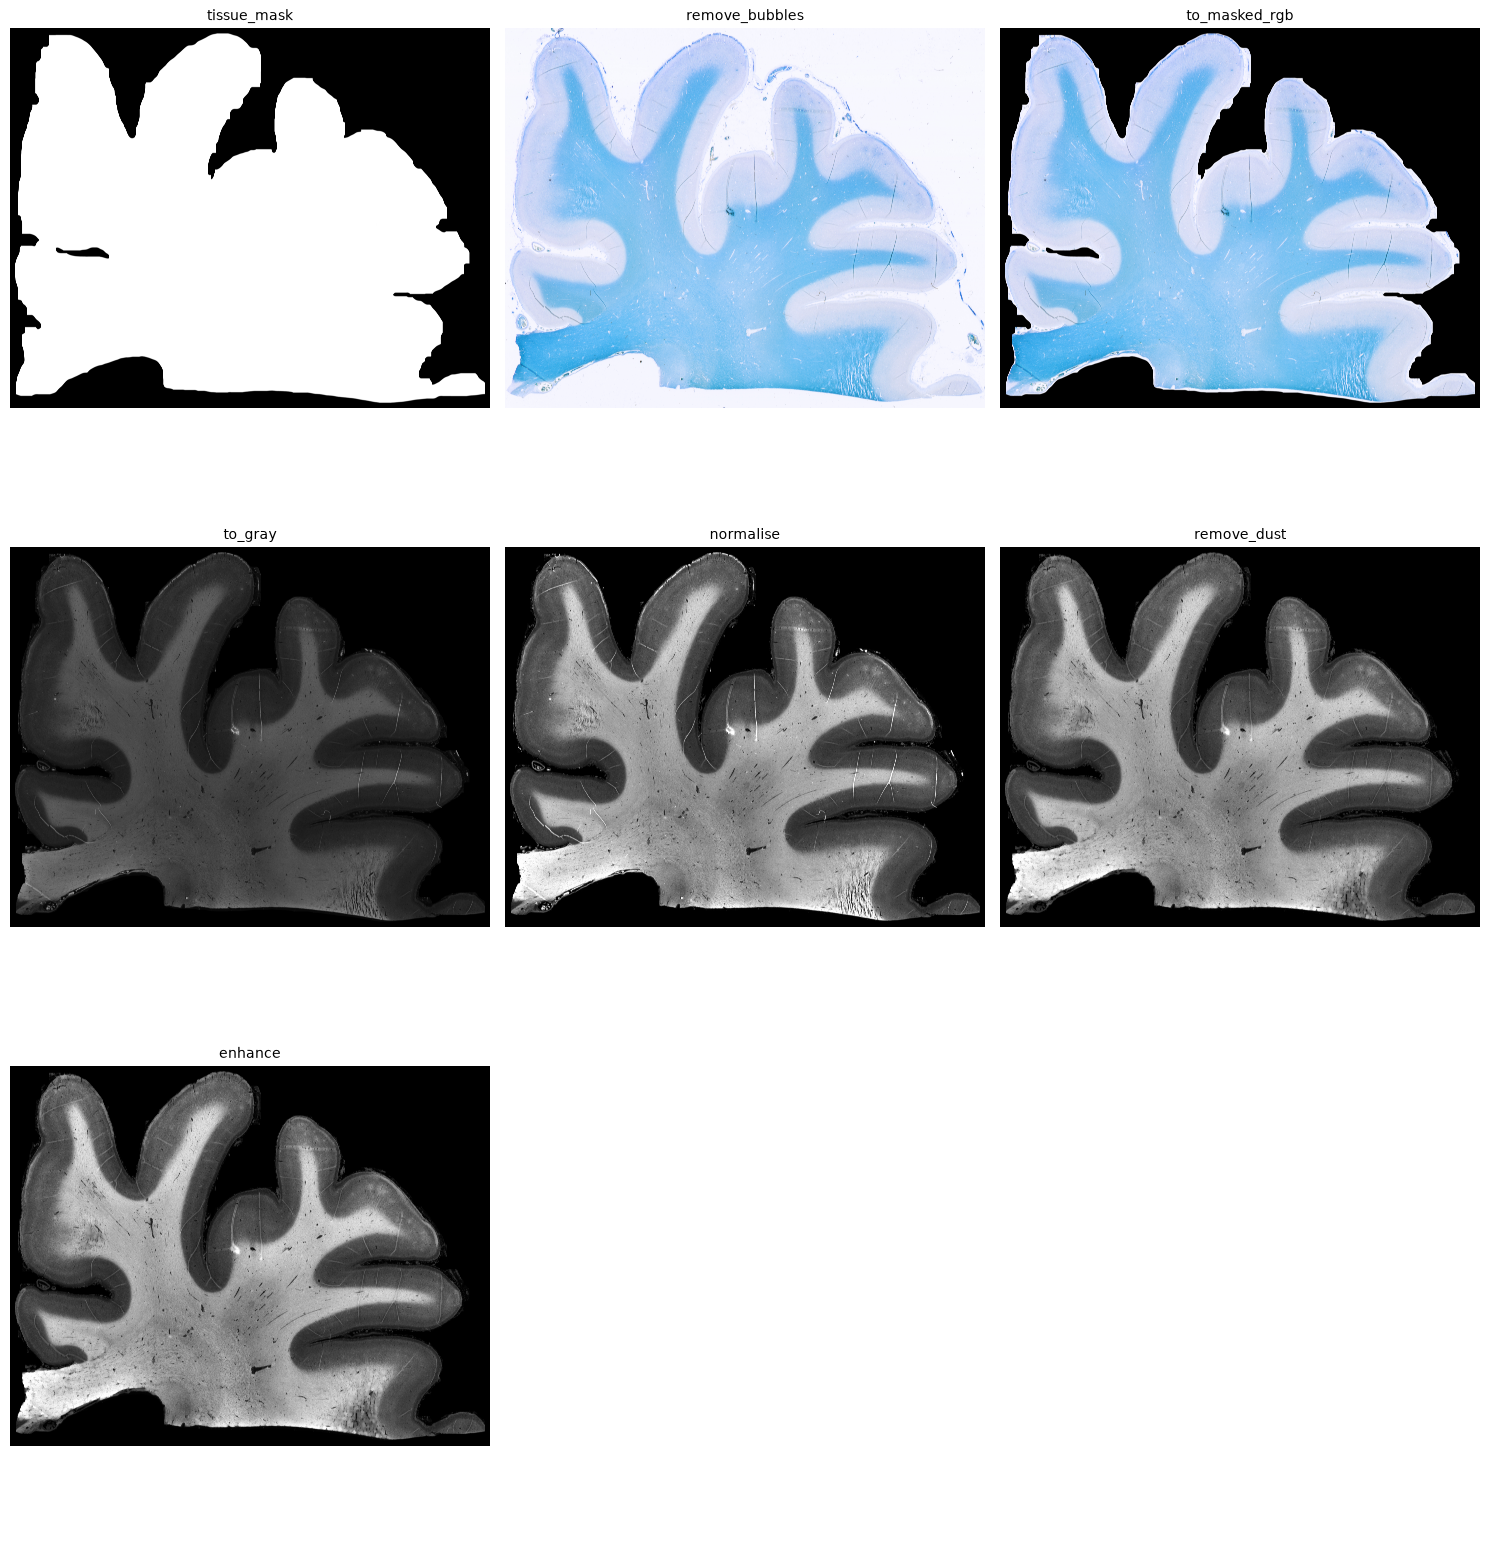

In [5]:
stages_shown = [(name, result.intermediates[name])
                for name in result.intermediates]

columns = 3
rows = (len(stages_shown) + columns - 1) // columns
fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 5.4 * rows),
                         squeeze=False)
for axis, (name, image) in zip(axes.flat, stages_shown):
    axis.imshow(image, cmap=None if image.ndim == 3 else "gray",
                vmin=None if image.ndim == 3 else 0,
                vmax=None if image.ndim == 3 else 255)
    axis.set_title(name, fontsize=10)
    axis.axis("off")
for axis in axes.flat[len(stages_shown):]:
    axis.axis("off")
plt.tight_layout()
plt.show()

In [6]:
for key, value in result.info.items():
    print(f"{key:24} {value}")

pixel_size_um            4.0
background_threshold     245
mask_blur_px             301
mask_open_px             275
border_components_dropped 1
printed_components_dropped 0
small_components_dropped 0
mask_area_px             76542556
source_shape_hw          [11480, 14492]
crop_origin_xy           [1306, 691]
output_shape_hw          [9446, 11952]
bubbles_found            4
bubbles_kept             0
bubble_area_px           0
normalise_low            9.0
normalise_high           112.0
dust_tophat_px           73
dust_threshold           69.48
dust_area_px             3672024
enhance                  clahe
mask_area_mm2            1224.681
mask_fraction            0.678
mask_components          1
mask_largest_fraction    1.0
mask_border_fraction     0.0
tissue_separability      2555.1
tissue_mean              118.47
tissue_std               58.14
